# 08. Beyond the paper: a detector signal through flux-ramp demodulation

This notebook goes beyond what the paper validates. The paper tests the model (the coupled-mode equation driven
through the measured bias-line transfer function $H(f)$) against measured flux-ramp and flux-pulse records
(Secs. V B and V C); here we use the validated model to look at what the transient after each ramp reset does to the
number a readout system actually reports, the flux-ramp demodulated detector signal of Eq. (5) (Sec. I,
`umux_cmt.demod`), and at how much of it is removed by discarding the first microseconds of every ramp period. It is
pure simulation, with no measured data: the device is `configs/nist_res2_2026-09-26.toml` and the bias line the pole
set of `03_flux_line_transfer_function`. Eight simulations of 400 $\mu$s (2-8 s each) and forty of a single ramp
period take most of the run time, under a minute in all.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import umux_cmt as uc
from umux_cmt.plotting import *      # use_style, save, SINGLE, DOUBLE, colours, grid
use_style()
DATA, CONFIGS, RESULTS = Path("../data"), Path("../configs"), Path("results")
store = uc.io.ValueStore(RESULTS / "values.json")

import time

CONFIG = CONFIGS / "nist_res2_2026-09-26.toml"
POLES = DATA / "flux_line_2026-10-02" / "flux_line_poles.npz"
F_PROBE = 5515.8e6          # Hz, the probe tone of the flux-ramp records of the paper
P_CHIP = -89                # dBm at the chip, the readout power of the paper
RATE = 100e3                # Hz, flux-ramp rate
N_PHI0 = 1.0                # flux quanta per ramp period, so f_m = N_PHI0 * RATE = RATE
T = 1 / RATE
N_PERIODS = 40
MAX_STEP = min(20e-9, T / 500)                          # s, largest solver step
PHI_RESET = store.value("IQPhiReset", default=0.184)   # ramp-line flux at the reset, calibrated in 06
PHI_DC = 0.05               # Phi0, constant detector flux under the pulse

## 1. The device and the two ramps

A ramp of exactly one flux quantum per period makes the modulation frequency equal to the ramp rate,
$f_m = n_{\Phi_0} f_\mathrm{fr} = 100$ kHz (Eq. 3), and makes the ideal reset invisible: the flux drops by exactly
$\Phi_0$, the SQUID is periodic in $\Phi_0$, and the resonator sees a perfectly smooth modulation. Through the bias
line the coil current cannot drop at once; it undershoots and rings at the 4.53 MHz pole of $H(f)$, and that ringing
is the reset transient. The detector couples through its own coil, the `Input` line with the design value
$M_\mathrm{in} = 246$ pH (no detector was connected in the measurements), so one flux quantum in the SQUID takes
$\Phi_0/M_\mathrm{in} = 8.4\ \mu$A. Nothing is fitted in this notebook: the device parameters come from the VNA sweep
of 26 Sep (`01`), the poles from the two-port of the line (`03`) and the reset flux from the 1 kHz record (`06`).

In [2]:
device = uc.load_config(CONFIG)
ch = device[0]
tf = uc.FluxLineTF.from_file(POLES)
M_FR, M_IN = ch.line("FluxRamp").M, ch.line("Input").M
print(ch)
print(tf)
for name, M in (("FluxRamp", M_FR), ("Input", M_IN)):
    print(f"  {name:<9} M = {M * 1e12:6.1f} pH   Phi0/M = {uc.Phi0 / M * 1e6:6.1f} uA per Phi0")

ramp_ideal = uc.signals.sawtooth(RATE, amplitude=N_PHI0, offset=PHI_RESET)
ramp_tf = tf.apply_periodic(ramp_ideal, T)
drives = {"through H(f)": ramp_tf, "ideal sawtooth": ramp_ideal}
COLOR = {"through H(f)": MODEL_TF, "ideal sawtooth": MODEL_IDEAL}
LABEL = {"through H(f)": "through $H(f)$", "ideal sawtooth": "ideal sawtooth"}

modes = tf.mode_table()                                   # (f, Q, tau) of every mode of the line
f_mode, Q_mode, tau_mode = modes[np.argmin(modes[:, 0])]  # the lowest one
tau = np.arange(0, T, 1e-9)
off = np.abs(ramp_tf(tau) - ramp_ideal(tau))
print(f"\nramp: {N_PHI0:g} Phi0 per period at {RATE / 1e3:g} kHz from a reset flux of {PHI_RESET:.4f} Phi0")
print(f"through H(f) the coil flux undershoots the reset flux by {PHI_RESET - ramp_tf(tau).min():.2f} Phi0 and is within "
      f"10 mPhi0 of the ideal ramp {tau[off > 0.01][-1] * 1e6:.1f} us, within 3 mPhi0 {tau[off > 0.003][-1] * 1e6:.1f} us "
      f"after the reset")
print(f"1/e decay of the {f_mode / 1e6:.2f} MHz mode {tau_mode * 1e9:.0f} ns; "
      f"resonator ring-up time 2/kappa = {ch.ring_up_time * 1e9:.0f} ns")

Channel('Ch1', f0=5515.689 MHz, Qr=9515, Qc=10475, Qi=103803, alpha=-0.086)
FluxLineTF(8 poles: 4.53 MHz (Q 5.6), 14.02 MHz (Q 6.2), 22.88 MHz (Q 11.3), 33.89 MHz (Q 7.4))
  FluxRamp  M =   14.4 pH   Phi0/M =  143.5 uA per Phi0
  Input     M =  246.0 pH   Phi0/M =    8.4 uA per Phi0

ramp: 1 Phi0 per period at 100 kHz from a reset flux of 0.1845 Phi0
through H(f) the coil flux undershoots the reset flux by 0.81 Phi0 and is within 10 mPhi0 of the ideal ramp 1.9 us, within 3 mPhi0 2.4 us after the reset
1/e decay of the 4.53 MHz mode 395 ns; resonator ring-up time 2/kappa = 549 ns


The quasi-static response `uc.static_response` is the steady-state $S_{21}$ at the probe tone and power against the
flux in the SQUID: what a resonator that followed the flux instantly would show. It is periodic in $\Phi_0$ and the
fluxes of the two lines add, so one flux quantum tabulated against the ramp line gives the quasi-static record of any
drive. Whatever the time-domain simulation shows beyond it is the resonator's own dynamics, which is how we tell the
coil's share of the transient from the resonator's below.

In [3]:
static = uc.static_response(device, F_PROBE, P_CHIP, phi_grid=np.linspace(0, 1, 4001))
quasi_static = lambda phi: static(np.mod(phi, 1))          # S21 for any total line flux in Phi0
slope = np.abs(np.gradient(static.s21, static.phi))
print(f"quasi-static |S21| from {np.abs(static.s21).min():.2f} to {np.abs(static.s21).max():.2f} over a flux quantum; "
      f"|dS21/dPhi| up to {slope.max():.1f} per Phi0, so 0.01 in S21 is {0.01 / slope.max() * 1e3:.1f} mPhi0 "
      f"where the response is steepest")

quasi-static |S21| from 0.09 to 0.96 over a flux quantum; |dS21/dPhi| up to 7.4 per Phi0, so 0.01 in S21 is 1.4 mPhi0 where the response is steepest


## 2. A detector-like input pulse

A detector pulse rises in 2 $\mu$s and decays in 30 $\mu$s, $\Phi_\mathrm{in} \propto e^{-t/\tau_f} - e^{-t/\tau_r}$,
normalised to a peak of $0.2\,\Phi_0$. It starts at $t = 60\ \mu$s, on a reset, and sits on a constant
$0.05\,\Phi_0$, so the detector is not at zero flux before the pulse either. The input line is driven directly (it
does not pass through the ramp's bias line), with the current $I_\mathrm{in} = \Phi_\mathrm{in}\Phi_0/M_\mathrm{in}$.
The constant alone, without the pulse, is the baseline: what the readout sees before the pulse arrives.

In [4]:
pulse = uc.signals.exponential_pulse(amplitude=0.2, t_rise=2e-6, t_fall=30e-6, period=1e-3, t_delay=60e-6)
constant = lambda c: (lambda t: c + 0 * t)
inputs = {"pulse": lambda t: PHI_DC + pulse(t), "no pulse": constant(PHI_DC)}
phi_in = inputs["pulse"]
I_in = uc.signals.flux_to_current(phi_in, M_IN, uc.Phi0)

t_fine = np.linspace(0, N_PERIODS * T, 40001)
k = np.argmax(phi_in(t_fine))
print(f"input flux {phi_in(0.0):.3f} Phi0 before the pulse, {phi_in(t_fine[k]):.3f} Phi0 at the peak "
      f"({t_fine[k] * 1e6:.1f} us), {phi_in(t_fine[-1]):.3f} Phi0 at the end")
print(f"input-line current {I_in(0.0) * 1e6:.2f} uA before the pulse, {I_in(t_fine[k]) * 1e6:.2f} uA at the peak")

input flux 0.050 Phi0 before the pulse, 0.250 Phi0 at the peak (65.8 us), 0.050 Phi0 at the end
input-line current 0.42 uA before the pulse, 2.10 uA at the peak


## 3. Four time-domain simulations

Each run integrates the equation of motion over 40 ramp periods (0-400 $\mu$s, output every 5 ns, internal steps of
at most 20 ns to resolve the ringing), starting from the static steady state 5 $\mu$s before $t = 0$. Each drive is
run with the pulse and with the baseline flux alone; a run takes about 5 s through $H(f)$ and half that with the ideal
ramp.

In [5]:
t = np.arange(0, N_PERIODS * T, 5e-9)


def run(ramp, phi, t_out=t):
    "Simulated S21 for a ramp-line flux and an input-line flux, both functions of time in Phi0."
    res = uc.simulate(device, F_PROBE, P_CHIP, t_out=t_out,
                      flux_ramp_current_func=uc.signals.flux_to_current(ramp, M_FR, uc.Phi0),
                      input_current_func=uc.signals.flux_to_current(phi, M_IN, uc.Phi0),
                      settle=5e-6, max_step=MAX_STEP)
    return res.s21


s21 = {}
for drive, ramp in drives.items():
    for case, phi in inputs.items():
        t0 = time.perf_counter()
        s21[drive, case] = run(ramp, phi)
        print(f"{drive:<15} {case:<9} {len(t)} samples in {time.perf_counter() - t0:.1f} s")

tau_t = t - np.floor(t / T + 1e-9) * T
gap = np.abs(s21["through H(f)", "no pulse"] - s21["ideal sawtooth", "no pulse"])
gap_qs = np.abs(quasi_static(ramp_tf(t) + PHI_DC) - quasi_static(ramp_ideal(t) + PHI_DC))
print(f"\nbaseline records: the two drives differ by up to {gap.max():.2f} in S21 after a reset and agree to within "
      f"0.01 from {tau_t[gap > 0.01].max() * 1e6:.1f} us after it")
print(f"quasi-static records (a resonator that follows the flux instantly): up to {gap_qs.max():.2f}, within 0.01 from "
      f"{tau_t[gap_qs > 0.01].max() * 1e6:.1f} us")

through H(f)    pulse     80000 samples in 4.6 s


through H(f)    no pulse  80000 samples in 4.6 s


ideal sawtooth  pulse     80000 samples in 2.4 s


ideal sawtooth  no pulse  80000 samples in 2.4 s

baseline records: the two drives differ by up to 0.59 in S21 after a reset and agree to within 0.01 from 2.7 us after it
quasi-static records (a resonator that follows the flux instantly): up to 0.91, within 0.01 from 2.8 us


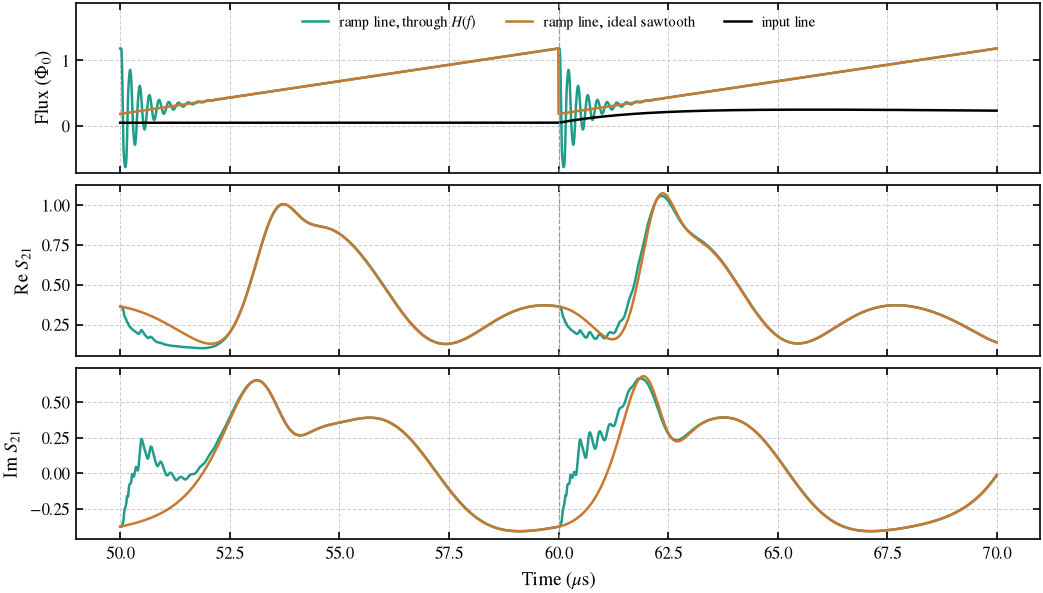

In [6]:
win = (t >= 50e-6) & (t < 70e-6)
fig, (ax_f, ax_i, ax_q) = plt.subplots(3, 1, figsize=(DOUBLE, 4.0), sharex=True)
for drive, ramp in drives.items():
    ax_f.plot(t[win] * 1e6, ramp(t[win]), color=COLOR[drive], label=f"ramp line, {LABEL[drive]}")
    ax_i.plot(t[win] * 1e6, s21[drive, "pulse"][win].real, color=COLOR[drive])
    ax_q.plot(t[win] * 1e6, s21[drive, "pulse"][win].imag, color=COLOR[drive])
ax_f.plot(t[win] * 1e6, phi_in(t[win]), color="black", label="input line")
for ax in (ax_f, ax_i, ax_q):
    ax.axvline(60, color=ZERO, ls="--", lw=0.6)
    grid(ax)
ax_f.set_ylabel(r"Flux ($\Phi_0$)")
ax_i.set_ylabel("Re $S_{21}$")
ax_q.set_ylabel("Im $S_{21}$")
ax_q.set_xlabel(r"Time ($\mu$s)")
ax_f.set_ylim(top=PHI_RESET + 1.7 * N_PHI0)
ax_f.legend(loc="upper center", fontsize=7, ncol=3)
save(fig, "08_s21_around_onset", RESULTS / "figures")
plt.show()

The two drives agree except in the first microseconds after each reset (the dashed line marks the reset at which
the pulse starts). There the coil flux of the $H(f)$ drive undershoots by 0.8 $\Phi_0$ and rings at 4.5 MHz, faster
than the resonator can follow: $S_{21}$ leaves the ideal-ramp record by up to 0.59, where a resonator that followed the flux
instantly would leave it by 0.91. It takes 2.7 $\mu$s to come back within 0.01, but the quasi-static record takes as
long: the flux response is so steep that 0.01 in $S_{21}$ can be as little as 1.4 m$\Phi_0$, and the coil is within
3 m$\Phi_0$ of the ideal ramp only after 2.4 $\mu$s. The late settling of $S_{21}$ is the coil's tail, not the resonator's memory; the
memory shows in the demodulated signal (step 6).

## 4. The readout signal: the probe phase about the circle centre

Every steady state of the resonator lies on one circle: setting $\dot a = 0$ gives
$S_{21} = 1 - \frac{e^{i\alpha}}{\cos\alpha}\,\frac{\kappa_c/2}{i\Delta + \kappa/2}$, a circle of centre
$c = 1 - e^{i\alpha}\kappa_c/(2\kappa\cos\alpha)$ and radius $r = \kappa_c/(2\kappa\cos\alpha)$, on which the angle
about the centre is $\theta = \mathrm{const} - 2\arctan(2\Delta/\kappa)$. Flux and readout power only move the
point along the circle, so the probe phase $\theta(t) = \arg(S_{21} - c)$ (Eq. 4 measured from the centre rather than
the origin, `uc.demod.probe_phase`) reads the detuning directly. With measured data $c$ is fitted to a slow-ramp
trace (`uc.fitting.fit_circle`); in the model it is known exactly, and we check that the quasi-static response lies on
it.

In [7]:
rot = np.exp(1j * ch.alpha) / np.cos(ch.alpha)
center = 1 - rot * ch.get_kappa_c() / (2 * ch.kappa)
radius = abs(rot) * ch.get_kappa_c() / (2 * ch.kappa)
theta_static = uc.demod.probe_phase(static.s21, center)
print(f"resonance circle: centre {center.real:.4f} {center.imag:+.4f}i, radius {radius:.4f}")
print(f"quasi-static response over one flux quantum: off the circle by at most "
      f"{np.max(np.abs(np.abs(static.s21 - center) - radius)):.0e}, probe phase swings over "
      f"{np.ptp(theta_static):.2f} rad ({np.degrees(np.ptp(theta_static)):.0f} deg) and returns")

theta = {key: uc.demod.probe_phase(z, center) for key, z in s21.items()}
for drive in drives:
    th = theta[drive, "pulse"]
    print(f"{drive:<15} theta in [{th.min():+.2f}, {th.max():+.2f}] rad, largest step between samples "
          f"{np.max(np.abs(np.diff(th))):.3f} rad, net change over 400 us {th[-1] - th[0]:+.4f} rad")

resonance circle: centre 0.5458 +0.0393i, radius 0.4559
quasi-static response over one flux quantum: off the circle by at most 4e-16, probe phase swings over 3.68 rad (211 deg) and returns
through H(f)    theta in [-5.85, -1.95] rad, largest step between samples 0.055 rad, net change over 400 us +0.0007 rad
ideal sawtooth  theta in [-5.87, -1.95] rad, largest step between samples 0.012 rad, net change over 400 us +0.0007 rad


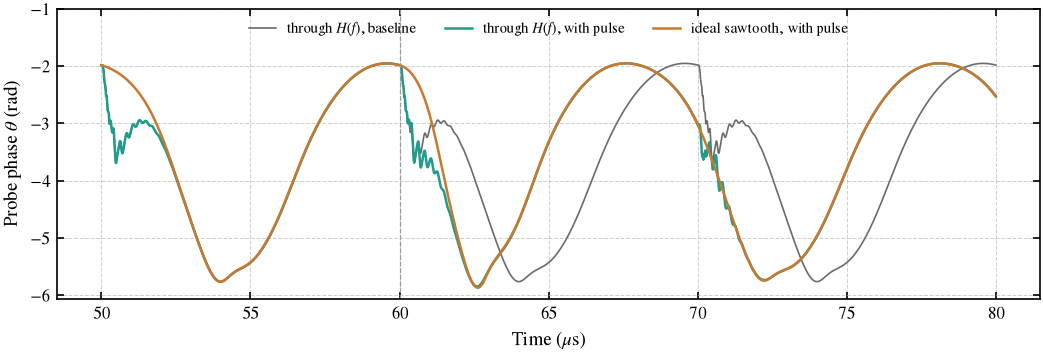

In [8]:
win = (t >= 50e-6) & (t < 80e-6)
fig, ax = plt.subplots(figsize=(DOUBLE, 2.4))
ax.plot(t[win] * 1e6, theta["through H(f)", "no pulse"][win], color=GRAY, lw=0.8, label="through $H(f)$, baseline")
for drive in drives:
    ax.plot(t[win] * 1e6, theta[drive, "pulse"][win], color=COLOR[drive], label=f"{LABEL[drive]}, with pulse")
ax.axvline(60, color=ZERO, ls="--", lw=0.6)
ax.set_ylim(top=-1.0)
ax.set_xlabel(r"Time ($\mu$s)")
ax.set_ylabel(r"Probe phase $\theta$ (rad)")
ax.legend(loc="upper center", fontsize=7, ncol=3)
grid(ax)
save(fig, "08_probe_phase", RESULTS / "figures")
plt.show()

Over each flux quantum the resonance moves through the probe tone and back, so $\theta$ swings out over about
3.7 rad and returns rather than winding through a full turn (the record has no net winding); Eq. (5) needs only a
signal that is periodic in the flux, and this one is strongly non-sinusoidal. Before the dashed line the record with
the pulse lies on the gray baseline; after it the pulse moves the whole waveform earlier in the ramp. The reset
transient is the fast wiggle at the start of each $H(f)$ period. The largest phase step between samples is far below
$\pi$, so the unwrapping is safe.

## 5. Demodulating a constant flux

`uc.demod.demodulate` evaluates Eq. (5) once per ramp period on the samples left after discarding the first $d$ of
each period. By default it fits $a\cos 2\pi f_m\tau + b\sin 2\pi f_m\tau + \mathrm{const}$ and returns
$\Delta\theta = \arctan(b/a)$, which over a whole period is exactly the sums of Eq. (5). For a rising ramp a positive
input flux moves the response earlier in the ramp, which with the sign convention of Eq. (5) lowers $\Delta\theta$, so
a record reads the flux $-(\Delta\theta - \Delta\theta_0)/2\pi$ relative to a reference record with $\Delta\theta_0$.
We start with a constant input flux $c$, read against $c = 0$: one ramp period after the settling is enough for that
(0.1 s per run), and we scan $c$ over a flux quantum.

In [9]:
C_GRID = np.arange(0, 1, 0.05)
D_CONST = (0.0, 2.0)                       # discards in us
t_one = np.arange(0, T, 5e-9)
wrap = lambda x: np.angle(np.exp(1j * x))
t0 = time.perf_counter()
dth = {}
for drive, ramp in drives.items():
    for c in C_GRID:
        th_c = uc.demod.probe_phase(run(ramp, constant(c), t_one), center)
        for d in D_CONST:
            dth[drive, c, d] = uc.demod.demodulate(th_c, t_one, RATE, N_PHI0, discard=d * 1e-6)[1][0]
read_err = {(drive, d): np.array([-wrap(dth[drive, c, d] - dth[drive, 0.0, d] + 2 * np.pi * c) / (2 * np.pi)
                                  for c in C_GRID]) for drive in drives for d in D_CONST}
store.record("DemodDCErrNoDiscard", 1e3 * np.interp(PHI_DC, C_GRID, read_err["through H(f)", 0.0]), "{:.1f}",
             "mPhi0, error of a constant 0.05 Phi0 read against no input, ramp through H(f), 100 kHz, 1 Phi0/period, "
             "no discard (08)")
print(f"{len(drives) * len(C_GRID)} one-period simulations in {time.perf_counter() - t0:.1f} s")
print("error of a constant flux read against no input flux, fundamental fit, in mPhi0")
for (drive, d), e in read_err.items():
    print(f"  {drive:<15} d = {d:g} us: from {1e3 * e.min():+6.1f} to {1e3 * e.max():+6.1f}, "
          f"at c = {PHI_DC:g} Phi0 {1e3 * np.interp(PHI_DC, C_GRID, e):+5.1f}")

40 one-period simulations in 4.6 s
error of a constant flux read against no input flux, fundamental fit, in mPhi0
  through H(f)    d = 0 us: from  -26.9 to   +7.9, at c = 0.05 Phi0  +5.9
  through H(f)    d = 2 us: from  -15.9 to  +17.8, at c = 0.05 Phi0  +8.7
  ideal sawtooth  d = 0 us: from   -0.0 to   +0.0, at c = 0.05 Phi0  +0.0
  ideal sawtooth  d = 2 us: from  -14.2 to  +18.1, at c = 0.05 Phi0  +8.2


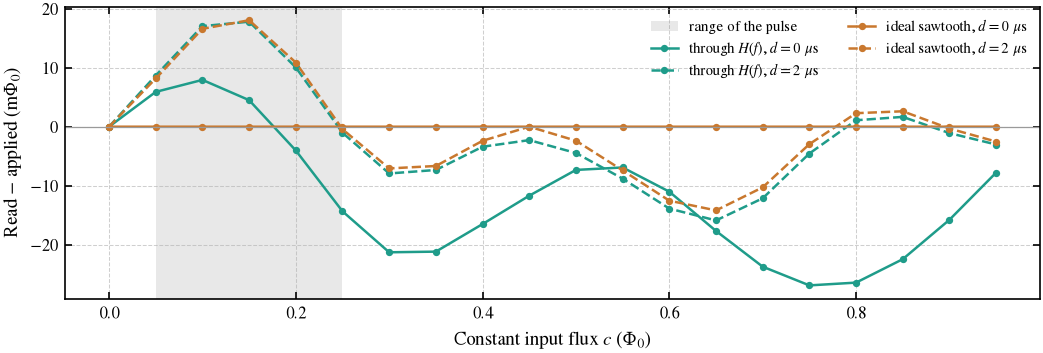

In [10]:
fig, ax = plt.subplots(figsize=(DOUBLE, 2.4))
ax.axvspan(PHI_DC, PHI_DC + 0.2, color=GRAY, alpha=0.15, lw=0, label="range of the pulse")
for (drive, d), e in read_err.items():
    ax.plot(C_GRID, 1e3 * e, color=COLOR[drive], ls="-" if d == 0 else "--", marker="o", ms=2.5,
            label=rf"{LABEL[drive]}, $d = {d:g}\ \mu$s")
ax.axhline(0, color=ZERO, lw=0.6)
ax.set_xlabel(r"Constant input flux $c$ ($\Phi_0$)")
ax.set_ylabel(r"Read $-$ applied (m$\Phi_0$)")
ax.legend(loc="upper right", fontsize=7, ncol=2)
grid(ax)
save(fig, "08_constant_flux_reading", RESULTS / "figures")
plt.show()

With the ideal ramp a constant flux is a pure time shift of the response, and at $d = 0$ Eq. (5) reads it exactly.
Through $H(f)$ the ringing stays at the reset while the response shifts under it, so the reading depends on where in
the response the transient falls: the error varies by 35 m$\Phi_0$ over a flux quantum, and the baseline's
$0.05\,\Phi_0$ already reads 5.9 m$\Phi_0$ high. Subtracting a baseline removes that offset, but a pulse moves along
the curve (shaded) and keeps the change. With 2 $\mu$s discarded the two drives agree, the transient is gone, but
the window is no longer a whole modulation period: the harmonics of the non-sinusoidal $\theta(t)$ are no longer
orthogonal to the fundamental and leak into $\Delta\theta$, by about as much and again depending on the flux.

## 6. Demodulating the pulse

The pulse record is read against the baseline record of the same drive, which removes the constant $0.05\,\Phi_0$
together with every constant phase offset, and compared with the applied pulse averaged over the samples kept in each
period. `n_harmonics=3` fits the second and third harmonic as well, which reduces the leakage on a shortened window
(at $d = 0$ it is identical to the fundamental-only fit). The difference between the two drives at the same $d$ and
fit is the cost of the reset transient, since everything else is common to both; demodulating the quasi-static
records in the same way shows what that cost would be for a resonator that followed the flux instantly.

In [11]:
def recovered_flux(th, drive, discard, n_harmonics=1, n_phi0=N_PHI0):
    "Pulse flux per ramp period in Phi0: Eq. (5) on the record with the pulse, minus the same on the baseline record."
    kw = dict(t_reset=0.0, discard=discard, n_harmonics=n_harmonics)
    t_p, dth_p = uc.demod.demodulate(th[drive, "pulse"], t, RATE, n_phi0, **kw)
    _, dth_0 = uc.demod.demodulate(th[drive, "no pulse"], t, RATE, n_phi0, **kw)
    return t_p, -(dth_p - dth_0) / (2 * np.pi)


def applied_flux(discard):
    "Applied pulse flux averaged over the samples kept in each ramp period."
    k = np.floor(t / T + 1e-9).astype(int)
    keep = t - k * T >= discard - 1e-12
    return np.array([pulse(t[keep & (k == p)]).mean() for p in range(N_PERIODS)])


theta_of_flux = lambda phi: np.interp(np.mod(phi, 1), static.phi, theta_static)
theta_qs = {(drive, case): theta_of_flux(ramp(t) + phi(t)) for drive, ramp in drives.items() for case, phi in inputs.items()}

rms = lambda x: np.sqrt(np.mean(x ** 2))
FITS = {"fundamental": 1, "3 harmonics": 3}
D_US = np.arange(0, 3.01, 0.25)                # discards in us; the table shows D_TABLE
D_TABLE = (0.0, 1.0, 2.0, 3.0)
rec, err, rec_qs = {}, {}, {}
for d in D_US:
    applied = applied_flux(d * 1e-6)
    for drive in drives:
        for fit, n in FITS.items():
            t_p, rec[drive, fit, d] = recovered_flux(theta, drive, d * 1e-6, n)
            err[drive, fit, d] = rec[drive, fit, d] - applied
        rec_qs[drive, d] = recovered_flux(theta_qs, drive, d * 1e-6)[1]
cost = {(fit, d): rec["through H(f)", fit, d] - rec["ideal sawtooth", fit, d] for fit in FITS for d in D_US}
cost_qs = {d: rec_qs["through H(f)", d] - rec_qs["ideal sawtooth", d] for d in D_US}

print(f"error of the recovered pulse over {N_PERIODS} periods, rms / peak in mPhi0")
print(f"{'':<19}{'fit':<13}" + "".join(f"{f'd = {d:g} us':>14}" for d in D_TABLE))
rows = [(drive, fit, [err[drive, fit, d] for d in D_TABLE]) for drive in drives for fit in FITS]
rows += [("H(f) - ideal", fit, [cost[fit, d] for d in D_TABLE]) for fit in FITS]
rows += [("same, quasi-static", "fundamental", [cost_qs[d] for d in D_TABLE])]
for name, fit, errors in rows:
    print(f"{name:<19}{fit:<13}" + "".join(f"{1e3 * rms(e):7.1f} /{1e3 * np.max(np.abs(e)):5.1f}" for e in errors))

sel = (D_US >= 0.75) & (D_US <= 2.0)
slope = np.polyfit(D_US[sel], np.log([rms(cost["fundamental", d]) for d in D_US[sel]]), 1)[0]
print(f"\nfrom d = 0.75 to 2 us the cost of the transient falls with a 1/e time of {-1 / slope:.2f} us "
      f"(ring-up time {ch.ring_up_time * 1e6:.2f} us, coil ringing {tau_mode * 1e6:.2f} us)")

error of the recovered pulse over 40 periods, rms / peak in mPhi0
                   fit                d = 0 us      d = 1 us      d = 2 us      d = 3 us
through H(f)       fundamental      3.2 / 16.9    3.6 / 11.2    4.2 / 13.4    7.3 / 34.8
through H(f)       3 harmonics      3.2 / 16.9    3.8 / 22.7    3.7 / 15.1    8.9 / 29.9
ideal sawtooth     fundamental      3.8 / 21.1    4.2 / 14.5    4.3 / 14.0    7.4 / 34.9
ideal sawtooth     3 harmonics      3.8 / 21.1    4.2 / 24.0    4.1 / 17.1    9.0 / 30.7
H(f) - ideal       fundamental      3.0 / 16.7    1.4 /  7.7    0.3 /  1.2    0.0 /  0.2
H(f) - ideal       3 harmonics      3.0 / 16.7    1.7 /  9.6    0.6 /  2.6    0.3 /  1.0
same, quasi-static fundamental      3.9 / 21.0    0.4 /  1.4    0.1 /  0.3    0.1 /  0.2

from d = 0.75 to 2 us the cost of the transient falls with a 1/e time of 0.71 us (ring-up time 0.55 us, coil ringing 0.40 us)


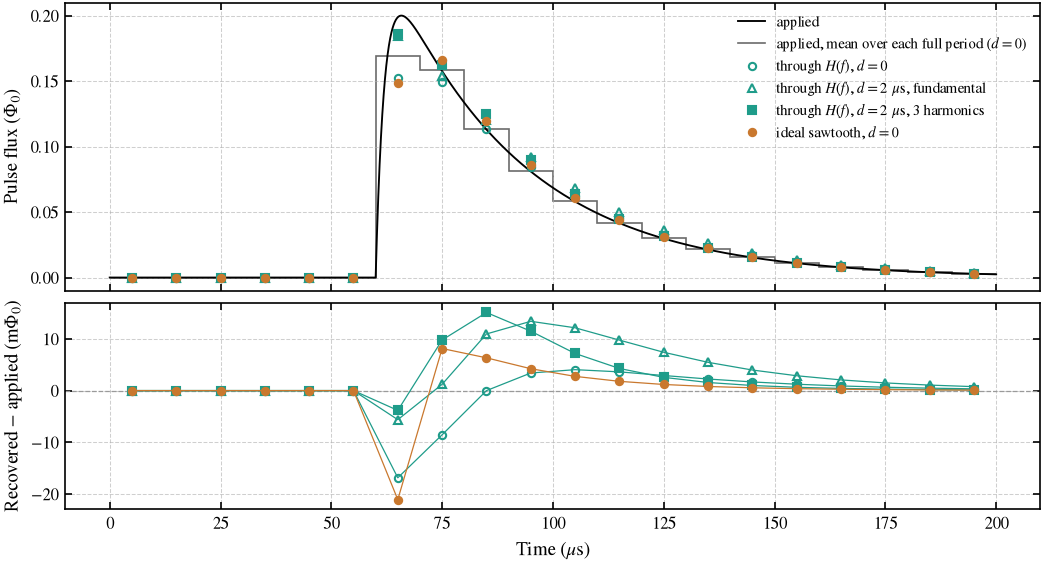

In [12]:
fig, (ax_f, ax_e) = plt.subplots(2, 1, figsize=(DOUBLE, 3.8), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
show = [("through H(f)", "fundamental", 0.0, "o", "none", "through $H(f)$, $d = 0$"),
        ("through H(f)", "fundamental", 2.0, "^", "none", r"through $H(f)$, $d = 2\ \mu$s, fundamental"),
        ("through H(f)", "3 harmonics", 2.0, "s", MODEL_TF, r"through $H(f)$, $d = 2\ \mu$s, 3 harmonics"),
        ("ideal sawtooth", "fundamental", 0.0, "o", MODEL_IDEAL, "ideal sawtooth, $d = 0$")]
m = t_p < 200e-6
tt = np.linspace(0, 200e-6, 4001)
ax_f.plot(tt * 1e6, pulse(tt), color="black", lw=0.9, label="applied")
ax_f.stairs(applied_flux(0.0)[m], np.arange(m.sum() + 1) * T * 1e6, baseline=None, color=GRAY, lw=0.8,
            label="applied, mean over each full period ($d = 0$)")
ax_e.axhline(0, color=ZERO, ls="--", lw=0.6)
for drive, fit, d, marker, face, label in show:
    style = dict(color=COLOR[drive], marker=marker, mfc=face, ms=3.5, lw=0.6)
    ax_f.plot(t_p[m] * 1e6, rec[drive, fit, d][m], ls="none", label=label, **style)
    ax_e.plot(t_p[m] * 1e6, 1e3 * err[drive, fit, d][m], **style)
ax_f.set_ylabel(r"Pulse flux ($\Phi_0$)")
ax_e.set_ylabel(r"Recovered $-$ applied (m$\Phi_0$)")
ax_e.set_xlabel(r"Time ($\mu$s)")
ax_f.legend(loc="upper right", fontsize=7)
for ax in (ax_f, ax_e):
    grid(ax)
save(fig, "08_recovered_flux", RESULTS / "figures")
plt.show()

In the lower panel each point is compared with the applied pulse averaged over the samples that were kept, so with
$d = 2\ \mu$s the reference is the mean over the last 8 $\mu$s of each period, not the gray stairs. Below, the rms of
these errors against the discard (left), and the cost of the transient alone, the difference between the two drives
(right).

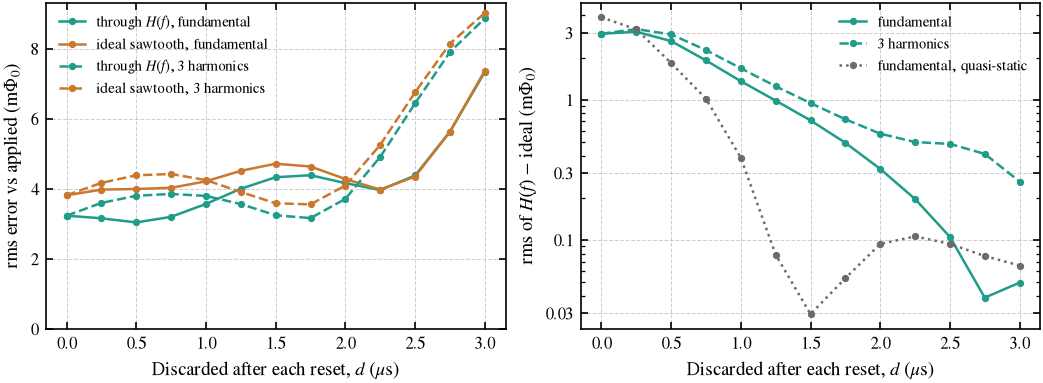

DemodErrNoDiscard          3.2 mPhi0
DemodErrDiscard2us         4.2 mPhi0
DemodErrDiscard2usHarm     3.7 mPhi0
DemodTransientNoDiscard    3.0 mPhi0
DemodTransient2us          0.3 mPhi0


In [13]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(DOUBLE, 2.6))
for fit, ls in zip(FITS, ("-", "--")):
    for drive in drives:
        ax_a.plot(D_US, [1e3 * rms(err[drive, fit, d]) for d in D_US], color=COLOR[drive], ls=ls, marker="o", ms=2.5,
                  label=f"{LABEL[drive]}, {fit}")
    ax_b.semilogy(D_US, [1e3 * rms(cost[fit, d]) for d in D_US], color=MODEL_TF, ls=ls, marker="o", ms=2.5, label=fit)
ax_b.semilogy(D_US, [1e3 * rms(cost_qs[d]) for d in D_US], color=GRAY, ls=":", marker="o", ms=2.5,
              label="fundamental, quasi-static")
ax_a.set_ylim(bottom=0)
ax_a.set_ylabel(r"rms error vs applied (m$\Phi_0$)")
ax_b.set_yticks([0.03, 0.1, 0.3, 1, 3], labels=["0.03", "0.1", "0.3", "1", "3"])
ax_b.yaxis.set_minor_formatter(plt.NullFormatter())
ax_b.set_ylabel(r"rms of $H(f)$ $-$ ideal (m$\Phi_0$)")
for ax in (ax_a, ax_b):
    ax.set_xlabel(r"Discarded after each reset, $d$ ($\mu$s)")
    ax.legend(loc="upper left" if ax is ax_a else "upper right", fontsize=7)
    grid(ax)
save(fig, "08_error_vs_discard", RESULTS / "figures")
plt.show()

store.record("DemodErrNoDiscard", 1e3 * rms(err["through H(f)", "fundamental", 0.0]), "{:.1f}",
             "mPhi0, rms error of the demodulated pulse against the applied pulse, read against the record without the "
             "pulse; ramp through H(f), 100 kHz, 1 Phi0/period, no discard (08)")
store.record("DemodErrDiscard2us", 1e3 * rms(err["through H(f)", "fundamental", 2.0]), "{:.1f}",
             "mPhi0, the same with 2 us discarded after each reset, fundamental-only fit as in Eq. (5) (08)")
store.record("DemodErrDiscard2usHarm", 1e3 * rms(err["through H(f)", "3 harmonics", 2.0]), "{:.1f}",
             "mPhi0, the same with 2 us discarded and the 2nd and 3rd harmonics in the fit (08)")
store.record("DemodTransientNoDiscard", 1e3 * rms(cost["fundamental", 0.0]), "{:.1f}",
             "mPhi0, rms of the recovered pulse through H(f) minus ideal sawtooth, no discard: the cost of the reset "
             "transient (08)")
store.record("DemodTransient2us", 1e3 * rms(cost["fundamental", 2.0]), "{:.1f}",
             "mPhi0, the same with 2 us discarded, fundamental-only fit (08)")
for name in ("DemodErrNoDiscard", "DemodErrDiscard2us", "DemodErrDiscard2usHarm", "DemodTransientNoDiscard",
             "DemodTransient2us"):
    print(f"{name:<24}{store.text(name):>6} mPhi0")

Through $H(f)$ the reset transient costs the pulse 3.0 m$\Phi_0$ rms (right panel, $d = 0$), most of it in the first
periods after the onset, where the pulse is largest. The cost falls with $d$ with a 1/e time of 0.7 $\mu$s, close to
the resonator's ring-up time and not the coil's 0.4 $\mu$s: a resonator that followed the flux instantly would pay
more at $d = 0$, since the real one smooths the fast swing, but 0.1 m$\Phi_0$ or less from $d = 1.25\ \mu$s on, since
the real one also remembers it. Against the applied pulse, discarding does not help here (left panel): 4.2 m$\Phi_0$ with
$d = 2\ \mu$s against 3.2 without a discard. The leakage of step 5 takes the transient's place, and one reading per
10 $\mu$s period cannot follow a pulse that changes within the period (3.8 m$\Phi_0$ with the ideal ramp, most of it
in the period of the onset).

## 7. Several flux quanta per period

With one flux quantum per ramp period every discard cuts into the only modulation period. With $n_{\Phi_0}$ flux
quanta per period, discarding exactly one modulation period, $d = T/n_{\Phi_0}$, leaves whole modulation periods, on
which the harmonics are orthogonal to the fundamental again. We repeat the pulse and baseline simulations with
$n_{\Phi_0} = 3$ ($f_m = 300$ kHz) at the same ramp rate; the reset now drops three flux quanta, so the coil rings
three times as hard. A run takes about 7 s through $H(f)$.

In [14]:
N3 = 3.0
ramp3 = uc.signals.sawtooth(RATE, amplitude=N3, offset=PHI_RESET)
drives3 = {"through H(f)": tf.apply_periodic(ramp3, T), "ideal sawtooth": ramp3}
theta3 = {}
for drive, ramp in drives3.items():
    for case, phi in inputs.items():
        t0 = time.perf_counter()
        theta3[drive, case] = uc.demod.probe_phase(run(ramp, phi), center)
        print(f"{drive:<15} {case:<9} in {time.perf_counter() - t0:.1f} s, "
              f"largest step of theta {np.max(np.abs(np.diff(theta3[drive, case]))):.3f} rad")

D3_US = (0.0, 1.0, 2.0, 1e6 * T / N3)
err3 = {}
for d in D3_US:
    applied = applied_flux(d * 1e-6)
    for drive in drives3:
        err3[drive, d] = recovered_flux(theta3, drive, d * 1e-6, n_phi0=N3)[1] - applied
store.record("DemodErr3Phi0NoDiscard", 1e3 * rms(err3["through H(f)", 0.0]), "{:.1f}",
             "mPhi0, rms error of the demodulated pulse, ramp through H(f), 100 kHz, 3 Phi0/period, no discard (08)")
store.record("DemodErr3Phi0DiscardT3", 1e3 * rms(err3["through H(f)", D3_US[-1]]), "{:.1f}",
             "mPhi0, the same with one modulation period (T/3) discarded after each reset (08)")

print(f"\n{N3:g} Phi0 per period, fundamental fit: error of the recovered pulse, rms / peak in mPhi0")
print(f"{'':<17}" + "".join(f"{f'd = {d:.3g} us':>14}" for d in D3_US))
rows = [(drive, [err3[drive, d] for d in D3_US]) for drive in drives3]
rows += [("H(f) - ideal", [err3["through H(f)", d] - err3["ideal sawtooth", d] for d in D3_US])]
for name, errors in rows:
    print(f"{name:<17}" + "".join(f"{1e3 * rms(e):7.1f} /{1e3 * np.max(np.abs(e)):5.1f}" for e in errors))

through H(f)    pulse     in 7.3 s, largest step of theta 0.051 rad


through H(f)    no pulse  in 7.2 s, largest step of theta 0.049 rad


ideal sawtooth  pulse     in 2.4 s, largest step of theta 0.027 rad


ideal sawtooth  no pulse  in 2.4 s, largest step of theta 0.027 rad

3 Phi0 per period, fundamental fit: error of the recovered pulse, rms / peak in mPhi0
                       d = 0 us      d = 1 us      d = 2 us   d = 3.33 us
through H(f)         3.5 / 11.4    1.8 /  8.3    0.6 /  2.0    0.7 /  3.5
ideal sawtooth       1.5 /  7.8    0.9 /  3.5    0.9 /  3.0    0.8 /  3.8
H(f) - ideal         4.4 / 15.5    1.8 /  9.6    0.4 /  1.1    0.1 /  0.3


Now the transient dominates the error without a discard: 3.5 m$\Phi_0$ rms through $H(f)$ against 1.5 with the ideal
ramp, an error that follows the pulse down its decay. Discarding 2 $\mu$s brings it to 0.6 m$\Phi_0$, and discarding one modulation
period to 0.7, the level of the ideal ramp, because the kept window holds two whole modulation periods and the
harmonics no longer leak. The ideal ramp also follows the changing pulse better than with one flux quantum (1.5
against 3.8 m$\Phi_0$ at $d = 0$), since each reading now draws on three modulation periods spread over the ramp period. In
this regime discarding the reset transient does what it is meant to.

## 8. What the reset transient costs

At 100 kHz and one flux quantum per period, the reset transient makes the readout nonlinear: the 4.53 MHz ringing is
pinned to the reset while the input flux moves the response along the ramp, so the reading error depends on the flux
and varies by 35 m$\Phi_0$ over a flux quantum (step 5). A baseline taken before the pulse removes what a
constant flux sees, 5.9 m$\Phi_0$ for the 0.05 $\Phi_0$ here, but not the change along the pulse: 3.0 m$\Phi_0$ rms
and up to 17 m$\Phi_0$ in one period for a 0.2 $\Phi_0$ pulse.

The coil's ringing decays with 395 ns but starts at 0.8 $\Phi_0$, and $S_{21}$ needs about 2.7 $\mu$s to settle, as
long as a resonator that followed the flux instantly: that settling is the coil's tail seen through the steep flux
response. In the demodulated signal the resonator matters. It smooths the swing but remembers it, so the cost falls
with about its ring-up time (0.7 against 0.55 $\mu$s), and a discard of 2 $\mu$s, about four ring-up times, takes it
to 0.3 m$\Phi_0$. Whether the readout gains from that depends on what is left. With one modulation period per ramp
period the shortened window lets the harmonics of $\theta$ leak into Eq. (5), and the error against the applied pulse
does not improve; with three flux quanta per period and one modulation period discarded it falls from 3.5 to
0.7 m$\Phi_0$, the level of the ideal ramp. In a real readout every discarded sample also costs signal-to-noise (this
simulation has no noise). Since the transient is deterministic and the model reproduces it (Secs. V B and V C), the
samples need not be thrown away: one could demodulate each period against the modelled waveform instead of a
sinusoid, or pre-distort the ramp with $H^{-1}(f)$, as the paper's outlook (Sec. VI) suggests.

## What to try next

Each of these edits overwrites the `Demod*` entries of `results/values.json`; rerun the notebook unchanged to restore
them.

* **A faster ramp.** Set `RATE = 200e3`: the transient's cost at $d = 0$ grows about fivefold, to 16 m$\Phi_0$ rms,
  and the 2 $\mu$s discard that removes it leaves a 3 $\mu$s window on which the fundamental-only fit is off by about
  20 m$\Phi_0$ rms, with either drive.
* **The slew-rate limit.** Raise the pulse to `amplitude=0.8` in step 2: the mean flux then jumps by 0.68 $\Phi_0$
  from one ramp period to the next, more than half a flux quantum, so the unwrapping of $\Delta\theta$ across periods
  picks the wrong branch and the recovered pulse is off by a whole flux quantum from then on.
* **Readout noise.** Add complex white noise to each record before computing $\theta$, e.g.
  `z + 1e-3 * (rng.normal(size=z.size) + 1j * rng.normal(size=z.size))` with `rng = np.random.default_rng(0)`, to see
  what each discarded sample costs in signal-to-noise.

To look at your own device, write a configuration for it (`configs/README.md`) and a pole set for its bias line
(`03`), set `F_PROBE` to a tone inside the flux range of its resonance, and rerun this notebook.